In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, pearsonr, f_oneway, kruskal

os.chdir(r"C:\Users\alosa\OneDrive\Desktop\RPDA8412\Research Project")
print("Current working directory:", os.getcwd())

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

cleaning_log = []

print("Libraries loaded")

Current working directory: C:\Users\alosa\OneDrive\Desktop\RPDA8412\Research Project
Libraries loaded


In [2]:
df = pd.read_csv("misinformation_metaphors_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (1500, 14)


,Sample_ID,Source_Type,Platform,Content_Text,Metaphor_Type,Emotion_Evoked,Political_Topic,Participant_ID,Belief_Score,Emotion_Intensity_Score,Belief_Label,Engagement_Likes,Engagement_Shares,Date_Posted
0,S0001,News Article,CNN,A fear-based metaphors metaphor about economy ...,Fear-based Metaphors,Hope,Economy,P229,2.5,4.8,0,671,229,2025-05-03
1,S0002,News Article,Fox News,A fear-based metaphors metaphor about immigrat...,Fear-based Metaphors,Fear,Immigration,P224,3.9,3.4,1,1052,1054,2025-05-01
2,S0003,News Article,CNN,A cognitive metaphors metaphor about tax polic...,Cognitive Metaphors,Anger,Tax Policy,P285,1.6,1.6,0,126,346,2025-04-11
3,S0004,Political Advertisement,YouTube,A nationalistic metaphors metaphor about immig...,Nationalistic Metaphors,Hope,Immigration,P095,1.2,4.5,0,1656,218,2025-03-28
4,S0005,Political Advertisement,TV,A artistic metaphor about tax policy evoking f...,Artistic,Fear,Tax Policy,P128,3.4,3.8,1,1650,181,2025-05-10


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Sample_ID                1500 non-null   str    
 1   Source_Type              1500 non-null   str    
 2   Platform                 1500 non-null   str    
 3   Content_Text             1500 non-null   str    
 4   Metaphor_Type            1500 non-null   str    
 5   Emotion_Evoked           1500 non-null   str    
 6   Political_Topic          1500 non-null   str    
 7   Participant_ID           1500 non-null   str    
 8   Belief_Score             1500 non-null   float64
 9   Emotion_Intensity_Score  1500 non-null   float64
 10  Belief_Label             1500 non-null   int64  
 11  Engagement_Likes         1500 non-null   int64  
 12  Engagement_Shares        1500 non-null   int64  
 13  Date_Posted              1500 non-null   str    
dtypes: float64(2), int64(3), str(9)
mem

In [4]:
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100
missing_summary = pd.DataFrame({
    "column": missing_count.index,
    "missing_count": missing_count.values,
    "missing_pct": missing_pct.values
}).sort_values(by="missing_count", ascending=False)

print("Missing values per column:")
print(missing_summary)

rows_before = len(df)
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate rows found: {duplicate_count}")

df = df.drop_duplicates()
rows_after = len(df)
print(f"Rows before removing duplicates: {rows_before}")
print(f"Rows after removing duplicates: {rows_after}")

cleaning_log.append({
    "step": 1, "column_affected": "all columns",
    "action_taken": "checked for missing values and duplicate rows",
    "reason": "identify data quality issues before preprocessing",
    "rows_before": rows_before, "rows_after": rows_after
})

Missing values per column:
                     column  missing_count  missing_pct
0                 Sample_ID              0          0.0
1               Source_Type              0          0.0
2                  Platform              0          0.0
3              Content_Text              0          0.0
4             Metaphor_Type              0          0.0
5            Emotion_Evoked              0          0.0
6           Political_Topic              0          0.0
7            Participant_ID              0          0.0
8              Belief_Score              0          0.0
9   Emotion_Intensity_Score              0          0.0
10             Belief_Label              0          0.0
11         Engagement_Likes              0          0.0
12        Engagement_Shares              0          0.0
13              Date_Posted              0          0.0

Duplicate rows found: 0
Rows before removing duplicates: 1500
Rows after removing duplicates: 1500


       Belief_Score  Emotion_Intensity_Score  Engagement_Likes  \
count   1500.000000              1500.000000       1500.000000   
mean       2.971800                 3.027400       1542.711333   
std        1.182617                 1.153069        847.360170   
min        1.000000                 1.000000        102.000000   
25%        1.900000                 2.000000        810.500000   
50%        3.000000                 3.000000       1559.000000   
75%        4.000000                 4.000000       2288.250000   
max        5.000000                 5.000000       2998.000000   

       Engagement_Shares  
count         1500.00000  
mean           622.41000  
std            344.00667  
min             20.00000  
25%            320.75000  
50%            636.00000  
75%            925.00000  
max           1200.00000  


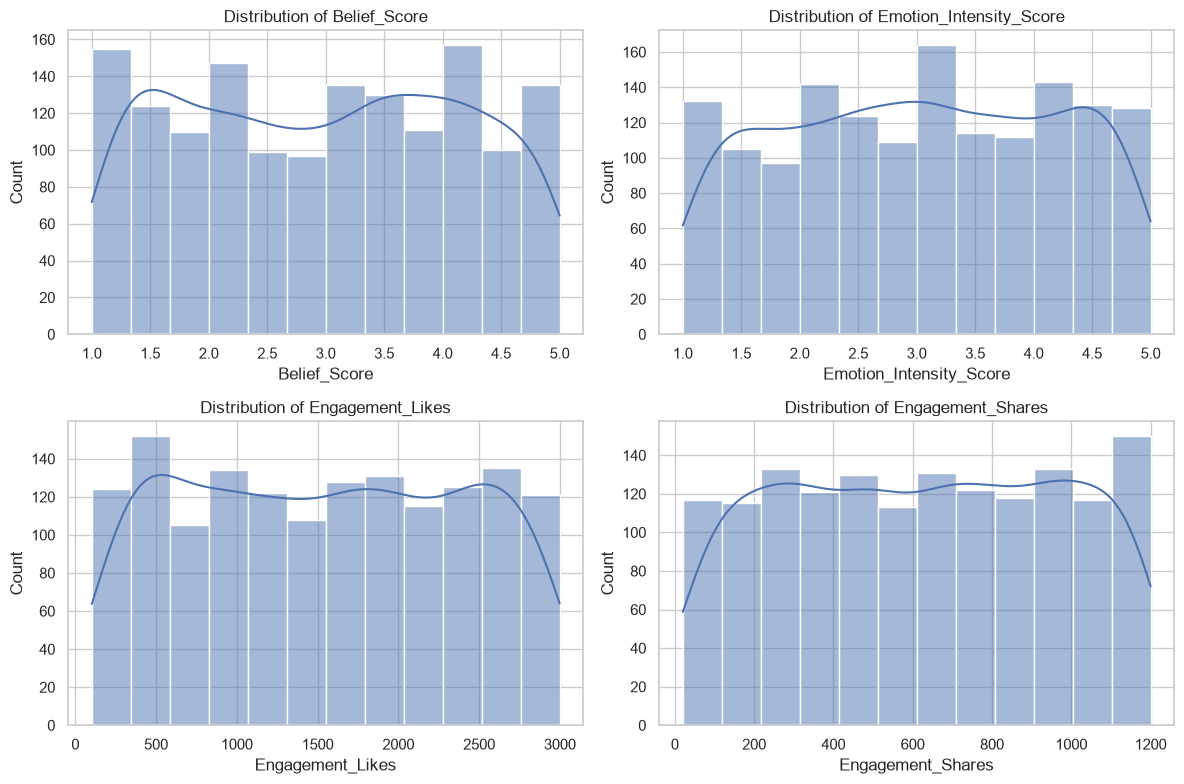

In [5]:
numeric_cols = ["Belief_Score", "Emotion_Intensity_Score", "Engagement_Likes", "Engagement_Shares"]

print(df[numeric_cols].describe())

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

plt.tight_layout()
plt.savefig("numeric_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
numeric_cols = ["Belief_Score", "Emotion_Intensity_Score", "Engagement_Likes", "Engagement_Shares"]

df[numeric_cols].describe()

,Belief_Score,Emotion_Intensity_Score,Engagement_Likes,Engagement_Shares
count,1500.000000,1500.000000,1500.000000,1500.00000
mean,2.971800,3.027400,1542.711333,622.41000
std,1.182617,1.153069,847.360170,344.00667
min,1.000000,1.000000,102.000000,20.00000
25%,1.900000,2.000000,810.500000,320.75000
50%,3.000000,3.000000,1559.000000,636.00000
75%,4.000000,4.000000,2288.250000,925.00000
max,5.000000,5.000000,2998.000000,1200.00000


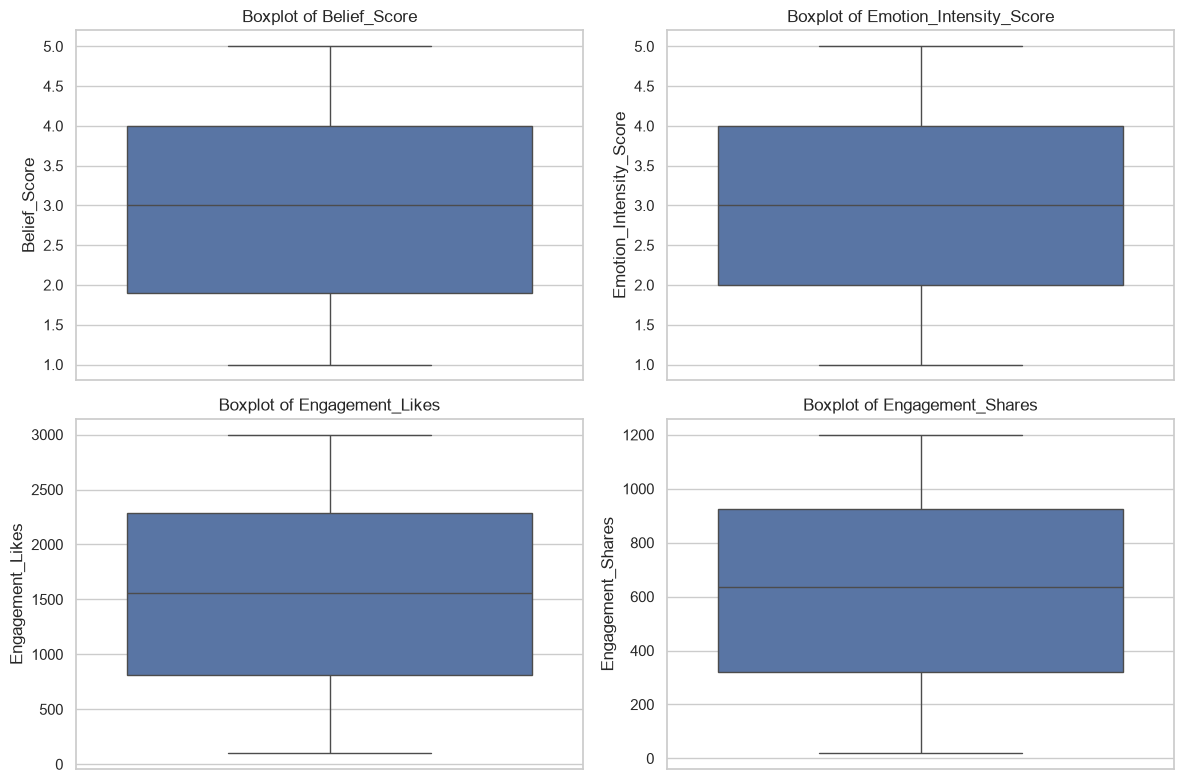

Outlier summary (IQR method):
                    column  lower_bound  upper_bound  outlier_count
0             Belief_Score       -1.250        7.150              0
1  Emotion_Intensity_Score       -1.000        7.000              0
2         Engagement_Likes    -1406.125     4504.875              0
3        Engagement_Shares     -585.625     1831.375              0


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.savefig("outlier_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

outlier_rows = []
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_count = len(outliers)
    outlier_rows.append({
        "column": col, "lower_bound": lower_bound, "upper_bound": upper_bound,
        "outlier_count": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_rows)
print("Outlier summary (IQR method):")
print(outlier_summary)

cleaning_log.append({
    "step": 2, "column_affected": ", ".join(numeric_cols),
    "action_taken": "flagged outliers using IQR method (1.5x IQR bounds), no rows removed",
    "reason": "assess presence of extreme values in numeric predictors before modelling",
    "rows_before": len(df), "rows_after": len(df)
})

In [8]:
desc_rows = []
for col in numeric_cols:
    desc_rows.append({
        "column": col, "mean": df[col].mean(), "median": df[col].median(),
        "std_dev": df[col].std(), "min": df[col].min(), "max": df[col].max(),
        "skewness": skew(df[col].dropna())
    })

descriptive_stats = pd.DataFrame(desc_rows)
print("Descriptive statistics:")
print(descriptive_stats)

Descriptive statistics:
                    column         mean  median     std_dev    min     max  \
0             Belief_Score     2.971800     3.0    1.182617    1.0     5.0   
1  Emotion_Intensity_Score     3.027400     3.0    1.153069    1.0     5.0   
2         Engagement_Likes  1542.711333  1559.0  847.360170  102.0  2998.0   
3        Engagement_Shares   622.410000   636.0  344.006670   20.0  1200.0   

   skewness  
0  0.008087  
1 -0.033903  
2  0.017455  
3 -0.017758  



Source_Type value counts:
Source_Type
News Article               520
Political Advertisement    513
Social Media Post          467
Name: count, dtype: int64

Platform value counts:
Platform
Facebook     328
TV           176
Breitbart    176
CNN          175
Fox News     169
YouTube      165
Instagram    160
Twitter      151
Name: count, dtype: int64

Metaphor_Type value counts:
Metaphor_Type
Fear-based Metaphors       394
Nationalistic Metaphors    387
Cognitive Metaphors        373
Artistic                   346
Name: count, dtype: int64

Emotion_Evoked value counts:
Emotion_Evoked
Disgust    323
Hope       305
Anxiety    296
Fear       291
Anger      285
Name: count, dtype: int64

Political_Topic value counts:
Political_Topic
Tax Policy     332
Immigration    309
Elections      306
Economy        285
Healthcare     268
Name: count, dtype: int64


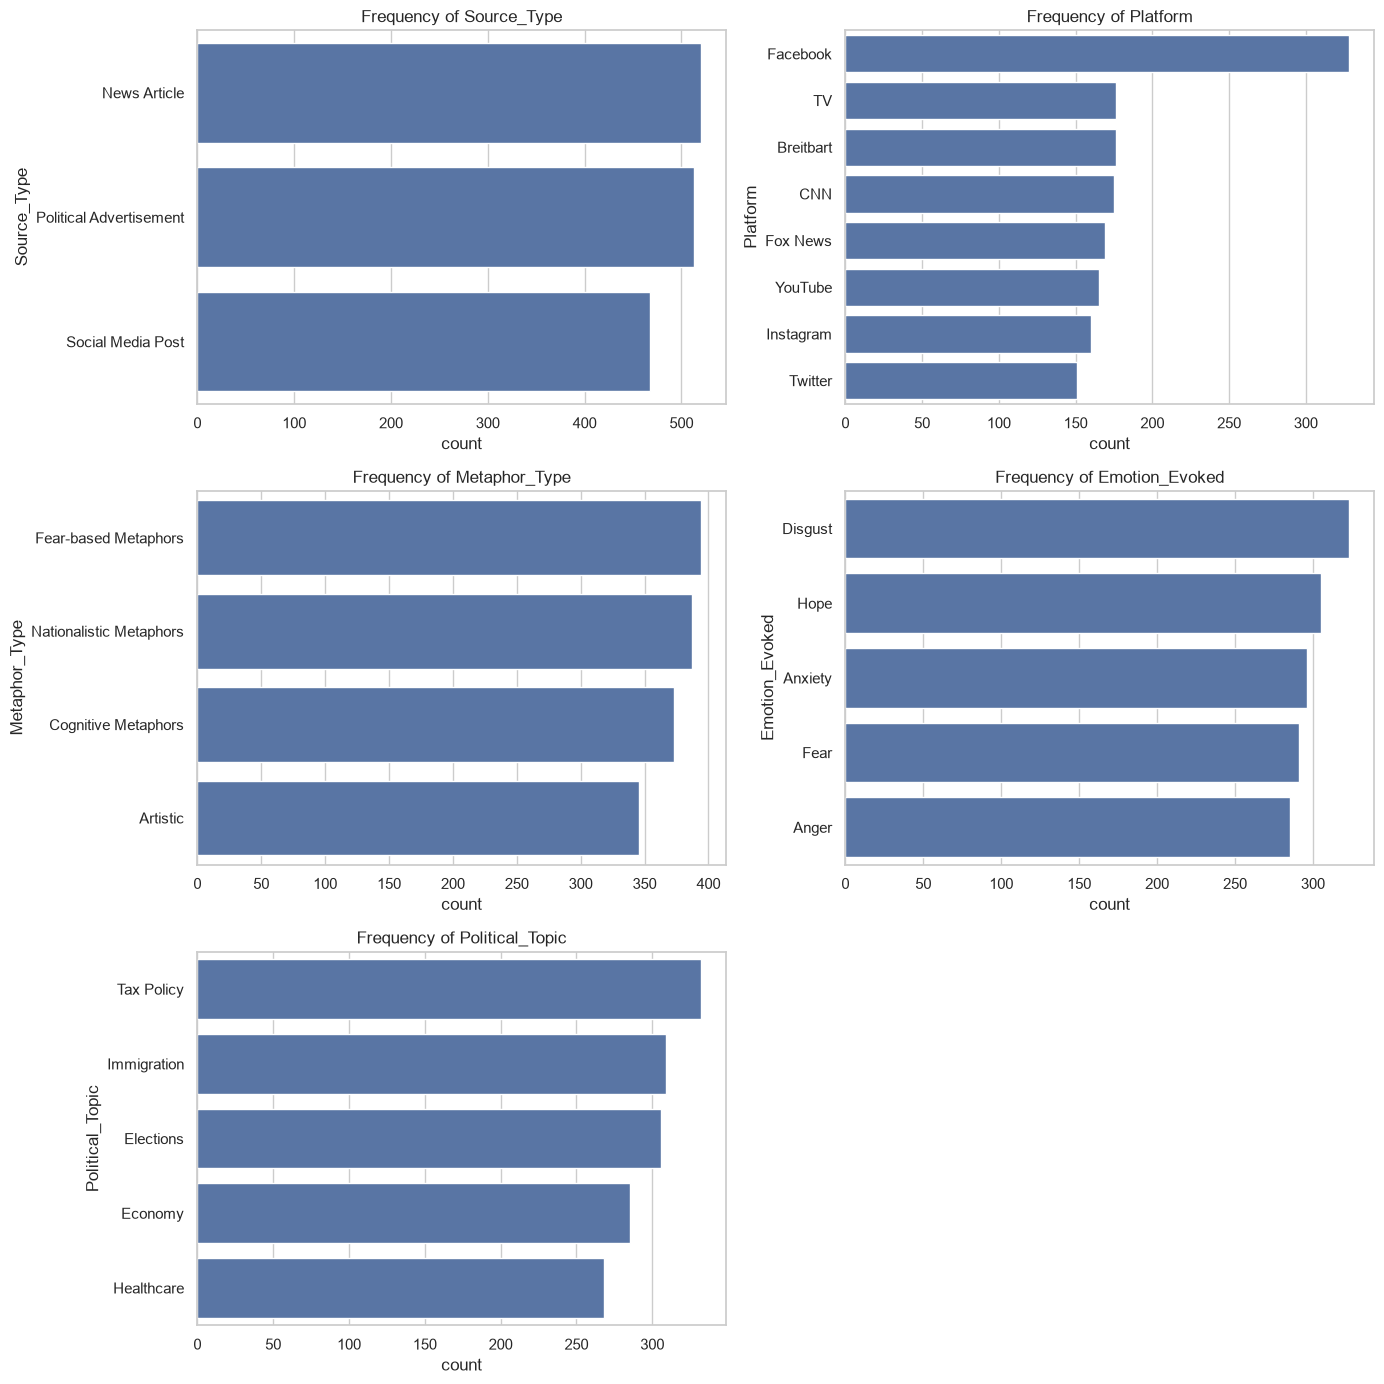

In [9]:
categorical_cols = ["Source_Type", "Platform", "Metaphor_Type", "Emotion_Evoked", "Political_Topic"]

for col in categorical_cols:
    print(f"\n{col} value counts:")
    print(df[col].value_counts())

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=axes[i])
    axes[i].set_title(f"Frequency of {col}")

if len(categorical_cols) < len(axes):
    for j in range(len(categorical_cols), len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig("categorical_frequencies.png", dpi=300, bbox_inches="tight")
plt.show()

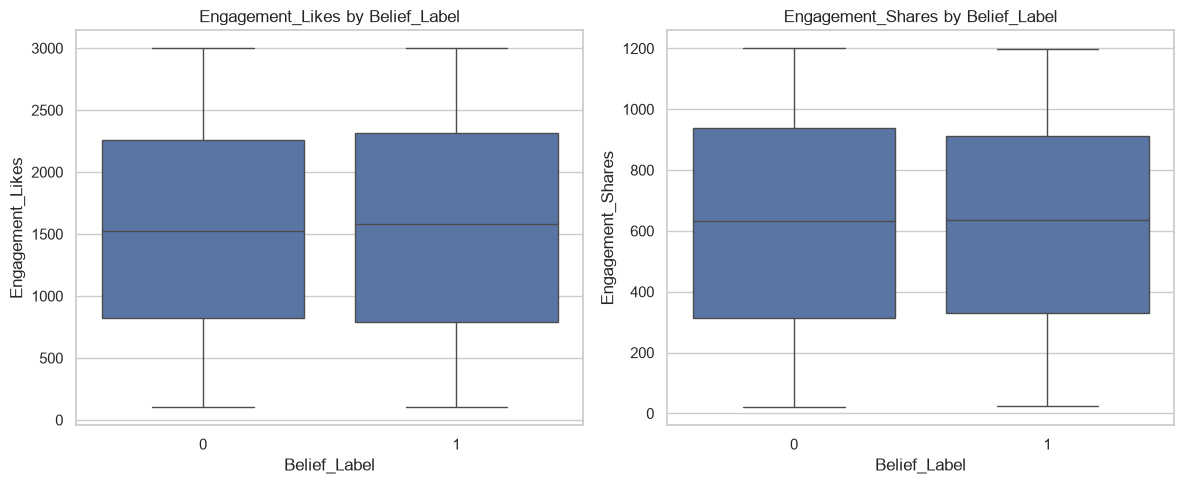

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(x="Belief_Label", y="Engagement_Likes", data=df, ax=axes[0])
axes[0].set_title("Engagement_Likes by Belief_Label")

sns.boxplot(x="Belief_Label", y="Engagement_Shares", data=df, ax=axes[1])
axes[1].set_title("Engagement_Shares by Belief_Label")

plt.tight_layout()
plt.savefig("engagement_by_belief_label.png", dpi=300, bbox_inches="tight")
plt.show()

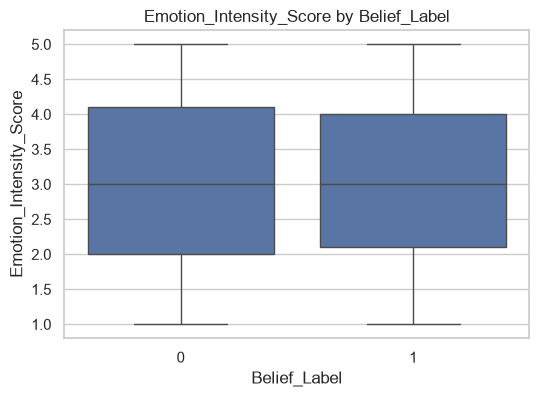

In [11]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="Belief_Label", y="Emotion_Intensity_Score", data=df)
plt.title("Emotion_Intensity_Score by Belief_Label")
plt.savefig("emotion_intensity_by_belief_label.png", dpi=300, bbox_inches="tight")
plt.show()

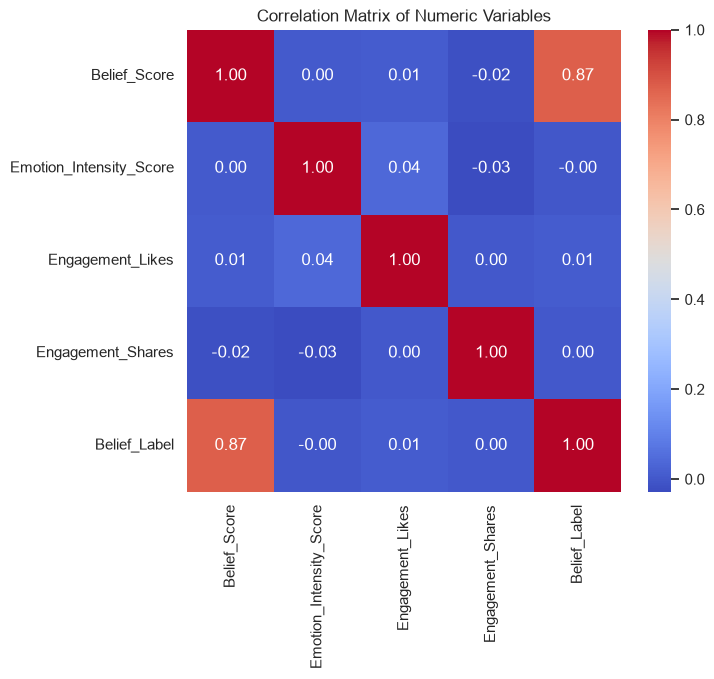

                         Belief_Score  Emotion_Intensity_Score  \
Belief_Score                 1.000000                 0.004329   
Emotion_Intensity_Score      0.004329                 1.000000   
Engagement_Likes             0.009961                 0.038266   
Engagement_Shares           -0.019361                -0.028424   
Belief_Label                 0.873699                -0.002480   

                         Engagement_Likes  Engagement_Shares  Belief_Label  
Belief_Score                     0.009961          -0.019361      0.873699  
Emotion_Intensity_Score          0.038266          -0.028424     -0.002480  
Engagement_Likes                 1.000000           0.003494      0.008941  
Engagement_Shares                0.003494           1.000000      0.000509  
Belief_Label                     0.008941           0.000509      1.000000  


In [12]:
corr_cols = ["Belief_Score", "Emotion_Intensity_Score", "Engagement_Likes", "Engagement_Shares", "Belief_Label"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Numeric Variables")
plt.savefig("correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print(corr_matrix)

Class balance summary:
   Belief_Label  count  percentage
1             0    732        48.8
0             1    768        51.2

Imbalance ratio (majority:minority): 1.05:1
Majority class is 51.20% of the data.


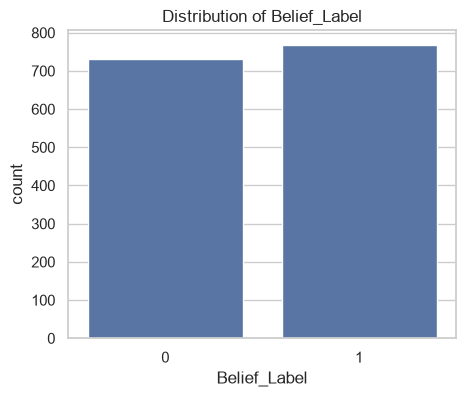

In [13]:
class_counts = df["Belief_Label"].value_counts()
class_pct = df["Belief_Label"].value_counts(normalize=True) * 100

class_balance_summary = pd.DataFrame({
    "Belief_Label": class_counts.index, "count": class_counts.values, "percentage": class_pct.values
}).sort_values(by="Belief_Label")

print("Class balance summary:")
print(class_balance_summary)

majority_count = class_counts.max()
minority_count = class_counts.min()
imbalance_ratio = majority_count / minority_count
majority_pct = class_pct.max()

print(f"\nImbalance ratio (majority:minority): {imbalance_ratio:.2f}:1")
print(f"Majority class is {majority_pct:.2f}% of the data.")

plt.figure(figsize=(5, 4))
sns.countplot(x="Belief_Label", data=df)
plt.title("Distribution of Belief_Label")
plt.savefig("class_balance.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
# H1: relationship between Emotion_Intensity_Score and Belief_Score
r_h1, p_h1 = pearsonr(df["Emotion_Intensity_Score"], df["Belief_Score"])
print("H1 - Emotion_Intensity_Score vs Belief_Score")
print(f"Pearson r = {r_h1:.4f}, p-value = {p_h1:.4f}")

alpha = 0.05
if p_h1 < alpha:
    print(f"Result: statistically significant at alpha = {alpha}. Reject H10.")
else:
    print(f"Result: not statistically significant at alpha = {alpha}. Fail to reject H10.")

H1 - Emotion_Intensity_Score vs Belief_Score
Pearson r = 0.0043, p-value = 0.8670
Result: not statistically significant at alpha = 0.05. Fail to reject H10.


In [15]:
# H2: relationship between Metaphor_Type (categorical, 4 groups) and Belief_Score
groups_h2 = [df[df["Metaphor_Type"] == cat]["Belief_Score"] for cat in df["Metaphor_Type"].unique()]

stat_h2, p_h2 = kruskal(*groups_h2)
print("H2 - Metaphor_Type groups vs Belief_Score (Kruskal-Wallis test)")
print(f"H statistic = {stat_h2:.4f}, p-value = {p_h2:.4f}")

if p_h2 < alpha:
    print(f"Result: statistically significant at alpha = {alpha}. Reject H20.")
else:
    print(f"Result: not statistically significant at alpha = {alpha}. Fail to reject H20.")

print("\nMedian Belief_Score per Metaphor_Type:")
print(df.groupby("Metaphor_Type")["Belief_Score"].median().sort_values(ascending=False))

H2 - Metaphor_Type groups vs Belief_Score (Kruskal-Wallis test)
H statistic = 5.3687, p-value = 0.1467
Result: not statistically significant at alpha = 0.05. Fail to reject H20.

Median Belief_Score per Metaphor_Type:
Metaphor_Type
Artistic                   3.1
Fear-based Metaphors       3.1
Cognitive Metaphors        3.0
Nationalistic Metaphors    2.8
Name: Belief_Score, dtype: float64


In [16]:
# H3: relationship between engagement volume and Belief_Score
r_likes, p_likes = pearsonr(df["Engagement_Likes"], df["Belief_Score"])
r_shares, p_shares = pearsonr(df["Engagement_Shares"], df["Belief_Score"])

print("H3 - Engagement_Likes vs Belief_Score")
print(f"Pearson r = {r_likes:.4f}, p-value = {p_likes:.4f}")
print("Result:", "statistically significant" if p_likes < alpha else "not statistically significant")

print("\nH3 - Engagement_Shares vs Belief_Score")
print(f"Pearson r = {r_shares:.4f}, p-value = {p_shares:.4f}")
print("Result:", "statistically significant" if p_shares < alpha else "not statistically significant")

H3 - Engagement_Likes vs Belief_Score
Pearson r = 0.0100, p-value = 0.6999
Result: not statistically significant

H3 - Engagement_Shares vs Belief_Score
Pearson r = -0.0194, p-value = 0.4537
Result: not statistically significant


In [17]:
# RQ2: relationship between Emotion_Intensity_Score and engagement volume
r_eng_likes, p_eng_likes = pearsonr(df["Emotion_Intensity_Score"], df["Engagement_Likes"])
r_eng_shares, p_eng_shares = pearsonr(df["Emotion_Intensity_Score"], df["Engagement_Shares"])

print("RQ2 - Emotion_Intensity_Score vs Engagement_Likes")
print(f"Pearson r = {r_eng_likes:.4f}, p-value = {p_eng_likes:.4f}")

print("\nRQ2 - Emotion_Intensity_Score vs Engagement_Shares")
print(f"Pearson r = {r_eng_shares:.4f}, p-value = {p_eng_shares:.4f}")

RQ2 - Emotion_Intensity_Score vs Engagement_Likes
Pearson r = 0.0383, p-value = 0.1385

RQ2 - Emotion_Intensity_Score vs Engagement_Shares
Pearson r = -0.0284, p-value = 0.2713


In [18]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import re

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from scipy.sparse import hstack, csr_matrix

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Modelling libraries loaded")

Modelling libraries loaded


In [19]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words]
    return " ".join(tokens)

df["Content_Text_Clean"] = df["Content_Text"].apply(clean_text)
print(df[["Content_Text", "Content_Text_Clean"]].head())

                                        Content_Text  \
0  A fear-based metaphors metaphor about economy ...   
1  A fear-based metaphors metaphor about immigrat...   
2  A cognitive metaphors metaphor about tax polic...   
3  A nationalistic metaphors metaphor about immig...   
4  A artistic metaphor about tax policy evoking f...   

                                  Content_Text_Clean  
0   fearbased metaphor metaphor economy evoking hope  
1  fearbased metaphor metaphor immigration evokin...  
2  cognitive metaphor metaphor tax policy evoking...  
3  nationalistic metaphor metaphor immigration ev...  
4          artistic metaphor tax policy evoking fear  


In [20]:
# Belief_Score is excluded from the feature set to avoid data leakage,
# since it carries a correlation of 0.87 with Belief_Label.
target = "Belief_Label"

categorical_features = ["Source_Type", "Platform", "Metaphor_Type", "Emotion_Evoked", "Political_Topic"]
numeric_features = ["Emotion_Intensity_Score", "Engagement_Likes", "Engagement_Shares"]
text_feature = "Content_Text_Clean"

X = df[categorical_features + numeric_features + [text_feature]]
y = df[target]

print("Feature columns used:", list(X.columns))
print("Target:", target)

Feature columns used: ['Source_Type', 'Platform', 'Metaphor_Type', 'Emotion_Evoked', 'Political_Topic', 'Emotion_Intensity_Score', 'Engagement_Likes', 'Engagement_Shares', 'Content_Text_Clean']
Target: Belief_Label


In [21]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp
)

print("Train size:", X_train.shape[0])
print("Validation size:", X_val.shape[0])
print("Test size:", X_test.shape[0])

Train size: 1050
Validation size: 225
Test size: 225


In [22]:
# One-hot encode categorical variables
encoder = OneHotEncoder(handle_unknown="ignore")
X_train_cat = encoder.fit_transform(X_train[categorical_features])
X_val_cat = encoder.transform(X_val[categorical_features])
X_test_cat = encoder.transform(X_test[categorical_features])

# TF-IDF vectorise the cleaned text
tfidf = TfidfVectorizer(max_features=2000)
X_train_text = tfidf.fit_transform(X_train[text_feature])
X_val_text = tfidf.transform(X_val[text_feature])
X_test_text = tfidf.transform(X_test[text_feature])

# Numeric features as sparse matrices
X_train_num = csr_matrix(X_train[numeric_features].values)
X_val_num = csr_matrix(X_val[numeric_features].values)
X_test_num = csr_matrix(X_test[numeric_features].values)

# Combine all features for Naive Bayes and Random Forest
X_train_combined = hstack([X_train_cat, X_train_num, X_train_text])
X_val_combined = hstack([X_val_cat, X_val_num, X_val_text])
X_test_combined = hstack([X_test_cat, X_test_num, X_test_text])

print("Combined training feature matrix shape:", X_train_combined.shape)

Combined training feature matrix shape: (1050, 45)


In [23]:
nb_model = MultinomialNB()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
nb_cv_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_combined, y_train), start=1):
    X_fold_train, X_fold_val = X_train_combined.tocsr()[train_idx], X_train_combined.tocsr()[val_idx]
    y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    nb_model.fit(X_fold_train, y_fold_train)
    fold_acc = nb_model.score(X_fold_val, y_fold_val)
    nb_cv_scores.append(fold_acc)
    print(f"Naive Bayes fold {fold} accuracy: {fold_acc:.4f}")

print(f"\nNaive Bayes mean CV accuracy: {np.mean(nb_cv_scores):.4f}")

# Fit on full training set for final test evaluation
nb_model.fit(X_train_combined, y_train)
nb_pred = nb_model.predict(X_test_combined)
nb_proba = nb_model.predict_proba(X_test_combined)[:, 1]

Naive Bayes fold 1 accuracy: 0.4762
Naive Bayes fold 2 accuracy: 0.4429
Naive Bayes fold 3 accuracy: 0.5286
Naive Bayes fold 4 accuracy: 0.5429
Naive Bayes fold 5 accuracy: 0.5000

Naive Bayes mean CV accuracy: 0.4981


In [24]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED)

rf_cv_scores = []
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_combined, y_train), start=1):
    X_fold_train, X_fold_val = X_train_combined.tocsr()[train_idx], X_train_combined.tocsr()[val_idx]
    y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    rf_model.fit(X_fold_train, y_fold_train)
    fold_acc = rf_model.score(X_fold_val, y_fold_val)
    rf_cv_scores.append(fold_acc)
    print(f"Random Forest fold {fold} accuracy: {fold_acc:.4f}")

print(f"\nRandom Forest mean CV accuracy: {np.mean(rf_cv_scores):.4f}")

rf_model.fit(X_train_combined, y_train)
rf_pred = rf_model.predict(X_test_combined)
rf_proba = rf_model.predict_proba(X_test_combined)[:, 1]

Random Forest fold 1 accuracy: 0.5810
Random Forest fold 2 accuracy: 0.4905
Random Forest fold 3 accuracy: 0.5143
Random Forest fold 4 accuracy: 0.5048
Random Forest fold 5 accuracy: 0.5524

Random Forest mean CV accuracy: 0.5286


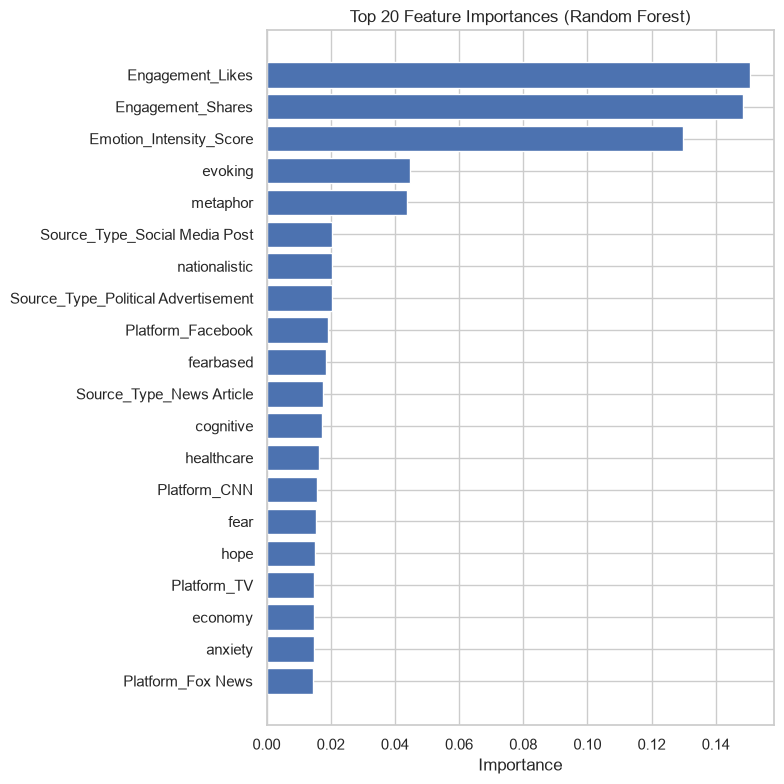

In [25]:
feature_names = (
    list(encoder.get_feature_names_out(categorical_features)) +
    numeric_features +
    list(tfidf.get_feature_names_out())
)

importances = rf_model.feature_importances_
top_n = 20
top_idx = np.argsort(importances)[-top_n:]

plt.figure(figsize=(8, 8))
plt.barh([feature_names[i] for i in top_idx], importances[top_idx])
plt.title(f"Top {top_n} Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("random_forest_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [26]:
%pip install "accelerate>=1.1.0"

Note: you may need to restart the kernel to use updated packages.


In [27]:
import torch
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
from torch.utils.data import Dataset

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)

class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx], truncation=True, padding="max_length",
            max_length=self.max_len, return_tensors="pt"
        )
        item = {key: val.squeeze(0) for key, val in encoding.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

train_dataset = TextDataset(X_train[text_feature], y_train, tokenizer)
val_dataset = TextDataset(X_val[text_feature], y_val, tokenizer)
test_dataset = TextDataset(X_test[text_feature], y_test, tokenizer)

training_args = TrainingArguments(
    output_dir="./bert_output",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="no",
    seed=RANDOM_SEED,
    logging_steps=50,
    report_to=[]
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset
)

trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
c:\Users\alosa\OneDriv

Epoch,Training Loss,Validation Loss
1,0.706471,0.694475
2,0.700155,0.694420
3,0.699525,0.694499


TrainOutput(global_step=198, training_loss=0.7019182648321595, metrics={'train_runtime': 1505.5053, 'train_samples_per_second': 2.092, 'train_steps_per_second': 0.132, 'total_flos': 207199956096000.0, 'train_loss': 0.7019182648321595, 'epoch': 3.0})

In [28]:
bert_raw_preds = trainer.predict(test_dataset)
bert_logits = bert_raw_preds.predictions
bert_proba = torch.softmax(torch.tensor(bert_logits), dim=1)[:, 1].numpy()
bert_pred = np.argmax(bert_logits, axis=1)

In [29]:
def evaluate_model(name, y_true, y_pred, y_proba):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_proba)

    print(f"\n{name} test set results")
    print(f"Accuracy:  {acc:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")

    return {"model": name, "accuracy": acc, "f1": f1, "precision": precision, "recall": recall, "roc_auc": roc_auc}

results = []
results.append(evaluate_model("Naive Bayes", y_test, nb_pred, nb_proba))
results.append(evaluate_model("Random Forest", y_test, rf_pred, rf_proba))
results.append(evaluate_model("BERT", y_test, bert_pred, bert_proba))

results_df = pd.DataFrame(results)
print("\nModel comparison:")
print(results_df)


Naive Bayes test set results
Accuracy:  0.5111
F1-score:  0.5259
Precision: 0.5214
Recall:    0.5304
ROC-AUC:   0.4829

Random Forest test set results
Accuracy:  0.5289
F1-score:  0.5546
Precision: 0.5366
Recall:    0.5739
ROC-AUC:   0.5228

BERT test set results
Accuracy:  0.5111
F1-score:  0.6765
Precision: 0.5111
Recall:    1.0000
ROC-AUC:   0.4913

Model comparison:
           model  accuracy        f1  precision    recall   roc_auc
0    Naive Bayes  0.511111  0.525862   0.521368  0.530435  0.482925
1  Random Forest  0.528889  0.554622   0.536585  0.573913  0.522767
2           BERT  0.511111  0.676471   0.511111  1.000000  0.491265


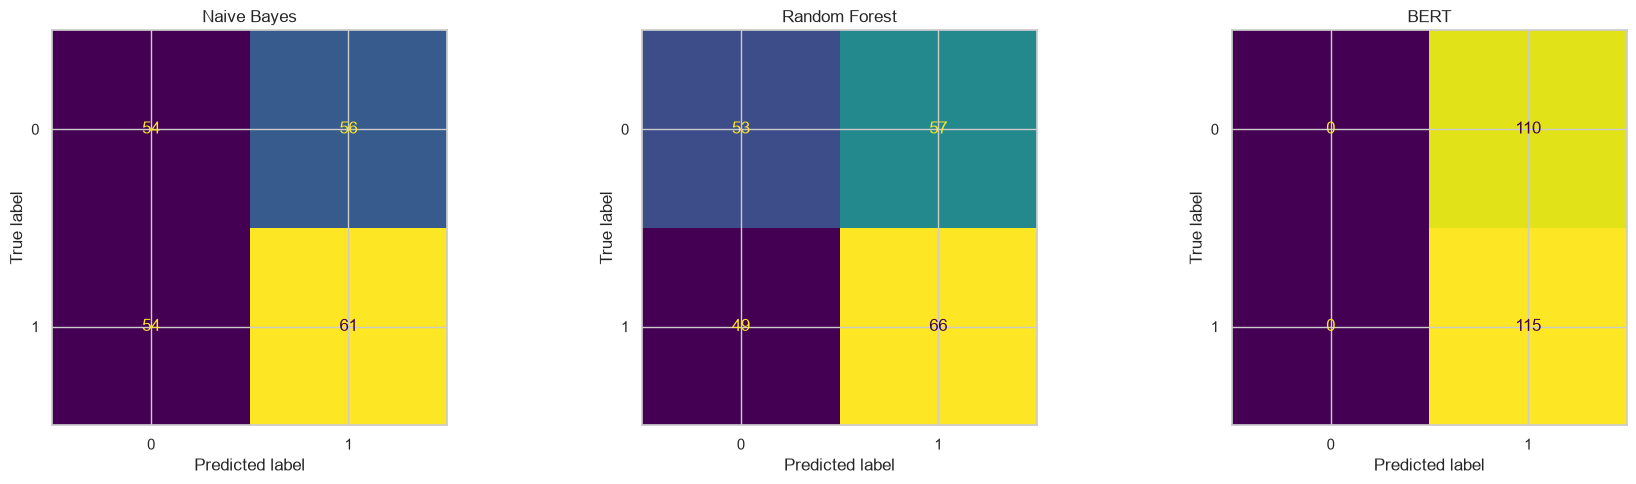

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, [("Naive Bayes", nb_pred), ("Random Forest", rf_pred), ("BERT", bert_pred)]):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

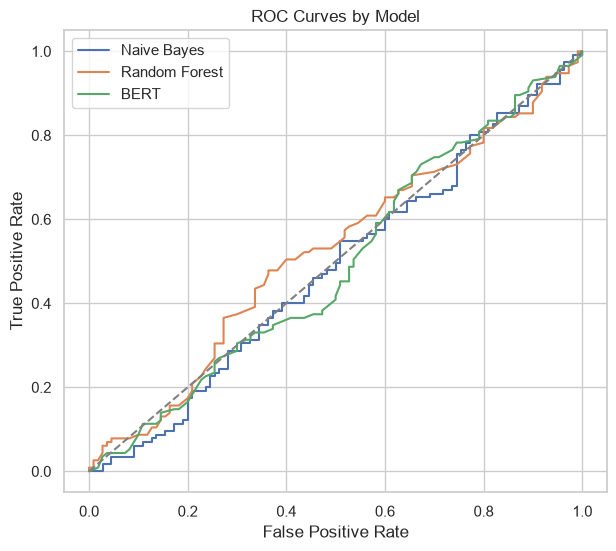

In [31]:
plt.figure(figsize=(7, 6))

for name, proba in [("Naive Bayes", nb_proba), ("Random Forest", rf_proba), ("BERT", bert_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves by Model")
plt.legend()
plt.savefig("roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()